# 03 · Model training and evaluation

**Decision question:** Can a risk ranking help a retention team prioritize a fixed outreach budget? We compare a transparent baseline and nonlinear models, tune a recall-oriented threshold on validation data, then evaluate once on a held-out test set.

All preprocessing is fitted within each training fold. The customer identifier is excluded. Results are benchmark evidence, not a production recommendation.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, brier_score_loss)

ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from datapulse.data import load_telco
from datapulse.modeling import candidate_models
from datapulse.metrics import threshold_for_recall
DATA_DIR = ROOT / 'data' / 'raw'
candidates = [DATA_DIR / 'Telco-Customer-Churn.csv', DATA_DIR / 'WA_Fn-UseC_-Telco-Customer-Churn.csv']
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None: raise FileNotFoundError('Place IBM CSV in data/raw/. See data/raw/README.md')
df = load_telco(data_path).drop_duplicates()
y = (df.pop('Churn') == 'Yes').astype(int)
X = df.drop(columns=['customerID'], errors='ignore')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, stratify=y, random_state=42)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=.25, stratify=y_train, random_state=43)
print('Fit / validation / test:', len(X_fit), len(X_val), len(X_test))

Fit / validation / test: 4225 1409 1409


## Compare candidates
Cross-validation happens only within the development training partition. Average precision (area under the precision-recall curve) is the primary ranking metric because churn is the minority class. ROC-AUC is included for context.

In [2]:
models = candidate_models(X_fit)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc', 'recall': 'recall'}
cv_rows = []
for name, estimator in models.items():
    scores = cross_validate(estimator, X_fit, y_fit, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({'model': name, **{f'{metric}_mean': scores[f'test_{metric}'].mean() for metric in scoring},
                    **{f'{metric}_sd': scores[f'test_{metric}'].std() for metric in scoring}})
cv_results = pd.DataFrame(cv_rows).sort_values('pr_auc_mean', ascending=False)
display(cv_results.round(3))
best_name = cv_results.iloc[0]['model']
best_model = models[best_name].fit(X_fit, y_fit)
val_prob = best_model.predict_proba(X_val)[:, 1]
threshold = threshold_for_recall(y_val, val_prob, minimum_recall=.70)
print(f'Validation-selected model: {best_name}; threshold for ≥70% recall: {threshold:.3f}')

,model,pr_auc_mean,roc_auc_mean,recall_mean,pr_auc_sd,roc_auc_sd,recall_sd
0,Logistic Regression,0.669,0.846,0.803,0.019,0.009,0.022
1,Random Forest,0.656,0.841,0.731,0.014,0.011,0.022
2,HistGradientBoosting,0.646,0.828,0.523,0.012,0.011,0.033


Validation-selected model: Logistic Regression; threshold for ≥70% recall: 0.614


## Final holdout evaluation
The threshold is frozen from validation. Avoid changing model or threshold after looking at these test metrics; if you do, the test set is no longer an unbiased final estimate.

,value
model,Logistic Regression
threshold,0.614312
test_pr_auc,0.634099
test_roc_auc,0.841166
test_precision,0.552239
test_recall,0.692513
test_f1,0.614472
test_balanced_accuracy,0.744807
test_brier,0.168982


              precision    recall  f1-score   support

    Retained       0.88      0.80      0.84      1035
     Churned       0.55      0.69      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409



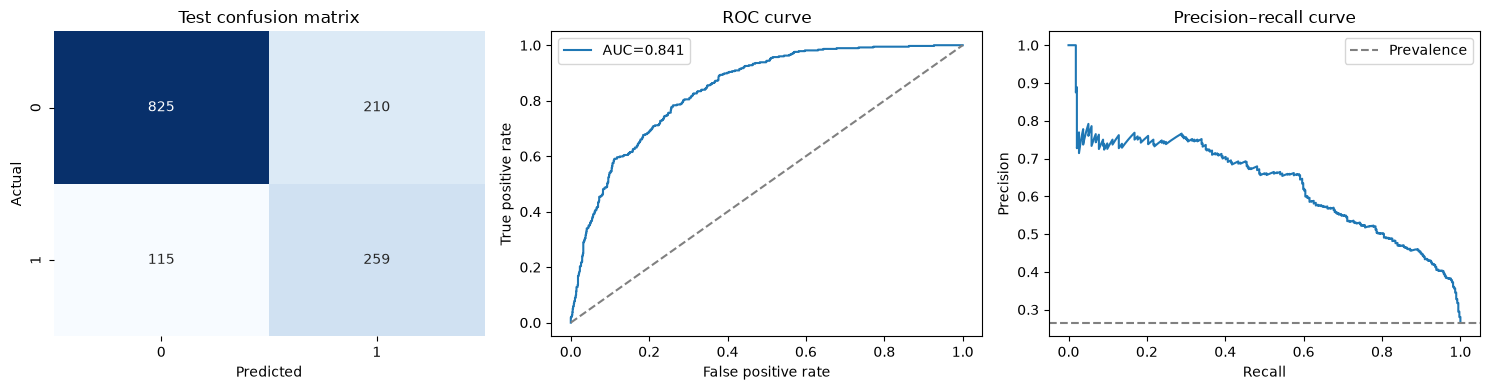

In [3]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype(int)
metrics = {'model': best_name, 'threshold': threshold, 'test_pr_auc': average_precision_score(y_test, test_prob),
           'test_roc_auc': roc_auc_score(y_test, test_prob), 'test_precision': precision_score(y_test, test_pred, zero_division=0),
           'test_recall': recall_score(y_test, test_pred), 'test_f1': f1_score(y_test, test_pred),
           'test_balanced_accuracy': balanced_accuracy_score(y_test, test_pred), 'test_brier': brier_score_loss(y_test, test_prob)}
display(pd.Series(metrics).to_frame('value'))
print(classification_report(y_test, test_pred, target_names=['Retained', 'Churned'], zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set(title='Test confusion matrix', xlabel='Predicted', ylabel='Actual')
fpr, tpr, _ = roc_curve(y_test, test_prob); axes[1].plot(fpr, tpr, label=f'AUC={metrics["test_roc_auc"]:.3f}'); axes[1].plot([0,1],[0,1],'--',color='grey'); axes[1].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate'); axes[1].legend()
precision, recall, _ = precision_recall_curve(y_test, test_prob); axes[2].plot(recall, precision); axes[2].axhline(y_test.mean(), linestyle='--', color='grey', label='Prevalence'); axes[2].set(title='Precision–recall curve', xlabel='Recall', ylabel='Precision'); axes[2].legend()
plt.tight_layout(); plt.show()

## Capacity-aware prioritization
Suppose the team can contact the highest-risk 10% of customers. Lift compares churn prevalence in that group with the overall prevalence. It describes ranking utility, not the effect of an offer; only an experiment can estimate incremental retention.

In [4]:
ranked = pd.DataFrame({'actual': y_test.to_numpy(), 'risk': test_prob}).sort_values('risk', ascending=False)
k = max(1, int(np.ceil(.10 * len(ranked))))
top_rate = ranked.head(k).actual.mean(); prevalence = ranked.actual.mean()
print(f'Top 10% test-set churn rate: {top_rate:.1%}; test prevalence: {prevalence:.1%}; lift: {top_rate/prevalence:.2f}×')
print(f'Test customers flagged at validation threshold: {test_pred.sum():,} / {len(test_pred):,}')

Top 10% test-set churn rate: 76.6%; test prevalence: 26.5%; lift: 2.89×
Test customers flagged at validation threshold: 469 / 1,409


## Model card and portfolio notes
**Intended use:** educational prioritization analysis on the public IBM benchmark.
**Out of scope:** real customer decisions, autonomous denial of service, or claiming that an offer prevents churn.
**Key limitations:** historical sample; unknown representativeness; likely temporal and population shift; threshold depends on outreach cost and capacity; subgroup performance and calibration should be audited before any operational use.
**Next experiment:** define contact cost and offer margin, choose a randomized holdout among eligible customers, and estimate incremental retention and net value.

Record the metrics above and compare against a simple policy baseline. Use only actual notebook outputs in your CV summary. Export a model only after freezing features, threshold, and versioned evaluation.